# 01 – Daten erkunden

Erster Blick auf das fertige Firm-Year-Panel: Wie viele Beobachtungen, wie viele Take-Private-Ziele (Positive), wie verteilen sie sich über die Jahre, und unterscheiden sich Ziele und Nicht-Ziele bei den Kennzahlen?

**Noch keine Stichprobenfilter** ($50M-Float, Finanzsektor, unsichere Deal-Abschlüsse) – die kommen im nächsten Schritt. Alle Zahlen hier beziehen sich also auf das ungefilterte Panel.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("..") / "data" / "processed"

# Zeitliche Aufteilung (wie im Design festgelegt): geschätzt wird auf 2012-17,
# 2018-19 ist ein Puffer (Embargo), getestet wird auf 2020-22.
TRAIN = range(2012, 2018)
EMBARGO = range(2018, 2020)
TEST = range(2020, 2023)

def split_of(year):
    """Ordnet ein Geschäftsjahr seinem Abschnitt zu."""
    if year in TRAIN:
        return "Train"
    if year in EMBARGO:
        return "Embargo"
    if year in TEST:
        return "Test"
    return "nach 2022"

## 1. Panel und Kennzahlen verbinden

Zwei Dateien: `firm_year_panel.csv` enthält pro Firma und Geschäftsjahr die **Labels** (wurde die Firma später Take-Private-Ziel?), `firm_year_ratios.csv` die **Kennzahlen**. Beide haben die Spalte `accession` – die eindeutige Nummer des 10-K-Berichts, aus dem die Zeile stammt. Darüber verbinden wir sie.

In [2]:
panel = pd.read_csv(DATA / "firm_year_panel.csv", dtype={"cik": str})
ratios = pd.read_csv(DATA / "firm_year_ratios.csv", dtype={"cik": str})

# Aus der Kennzahlen-Datei nur accession + die Kennzahlen nehmen;
# Firmenname, Jahr usw. stehen schon im Panel (sonst hätten wir sie doppelt).
ratio_cols = ["accession", "roa", "sales_growth_1y", "cash_ratio", "current_ratio", "leverage",
              "log_assets", "float_to_book", "float_to_earnings"]

# how="inner": nur Zeilen behalten, die in BEIDEN Dateien vorkommen.
# validate="one_to_one": bricht ab, falls eine accession doppelt vorkäme.
df = panel.merge(ratios[ratio_cols], on="accession", how="inner", validate="one_to_one")

print(f"Panel:       {len(panel):>7,} Zeilen")
print(f"Kennzahlen:  {len(ratios):>7,} Zeilen")
print(f"Verbunden:   {len(df):>7,} Zeilen")
print(f"Kennzahlen-Zeilen ohne Panel-Zeile (fallen weg): {len(ratios) - len(df):,}")

assert len(df) == 71_713, "Unerwartete Zeilenzahl!"
print("Check bestanden: 71,713 Zeilen")

Panel:        71,713 Zeilen
Kennzahlen:   72,161 Zeilen
Verbunden:    71,713 Zeilen
Kennzahlen-Zeilen ohne Panel-Zeile (fallen weg): 448
Check bestanden: 71,713 Zeilen


**Ergebnis:** Alle 71.713 Panel-Zeilen haben passende Kennzahlen, der Check besteht. Die 448 übrigen Kennzahlen-Zeilen gehören zu Jahren, die beim Neubau des Panels nach der Form-25-Korrektur (22.09.) entfernt wurden (Jahre nach einem Deal); sie fallen hier korrekt weg.

## 2. Nur Zeilen mit vollständig beobachtetem 3-Jahres-Fenster

Das Label `y_pe_main_h3` fragt: *Wird die Firma in den nächsten 3 Jahren Take-Private-Ziel?* Für die letzten Jahre im Datensatz (2023–2025) kennen wir die Antwort noch nicht vollständig – diese Zukunft liegt außerhalb der Daten. `h3_observed` markiert die Zeilen, bei denen die vollen 3 Jahre beobachtet sind.

Zwei Outcome-Definitionen: **main** = PE-ähnliche Käufer (Sponsor-Struktur, auch wenn der Käufer kein klassischer PE-Fonds ist), **strict** = nur institutionelle PE-Fonds.

In [3]:
obs = df[df["h3_observed"]].copy()
obs["split"] = obs["fiscal_year"].map(split_of)

print(f"Zeilen mit beobachtetem 3-Jahres-Fenster: {len(obs):,} "
      f"(Geschäftsjahre {obs['fiscal_year'].min()}-{obs['fiscal_year'].max()}, {obs['cik'].nunique():,} Firmen)")

rows = []
for y in ["y_pe_main_h3", "y_pe_strict_h3"]:
    rows.append({
        "Outcome": y,
        "Positive Zeilen": int(obs[y].sum()),
        "Anteil Positive": f"{obs[y].mean():.2%}",
        "Firmen mit >=1 Positiv": obs.loc[obs[y] == 1, "cik"].nunique(),
    })
pd.DataFrame(rows).set_index("Outcome")

Zeilen mit beobachtetem 3-Jahres-Fenster: 61,240 (Geschäftsjahre 2012-2022, 10,743 Firmen)


,Positive Zeilen,Anteil Positive,Firmen mit >=1 Positiv
Outcome,,,
y_pe_main_h3,327,0.53%,136
y_pe_strict_h3,277,0.45%,115


**Ergebnis:** Es bleiben 61.240 Firmenjahre (2012–2022). Nur 0,53 % davon sind positiv (327 Zeilen von 136 Firmen) – ein Take-Private ist also ein seltenes Ereignis, etwa 1 von 190 Firmenjahren. Eine Firma zählt bis zu dreimal positiv, weil das Label jedes der drei Jahre vor dem Deal markiert; deshalb gibt es mehr positive Zeilen als Firmen. Diese Zahlen sind noch ungefiltert und darum höher als die 282 der späteren Modellstichprobe.

## 3. Positive pro Geschäftsjahr

In [4]:
# Tabelle: Gesamtzeilen und Positive (beide Outcomes) pro Jahr
by_year = (obs.groupby("fiscal_year")
              .agg(Abschnitt=("split", "first"),
                   Zeilen=("accession", "size"),
                   Positive_main=("y_pe_main_h3", "sum"),
                   Positive_strict=("y_pe_strict_h3", "sum")))
by_year["Anteil_main"] = (by_year["Positive_main"] / by_year["Zeilen"]).map("{:.2%}".format)
by_year

,Abschnitt,Zeilen,Positive_main,Positive_strict,Anteil_main
fiscal_year,,,,,
2012,Train,6200,32,23,0.52%
2013,Train,6092,26,21,0.43%
2014,Train,6003,32,25,0.53%
2015,Train,5691,29,26,0.51%
2016,Train,5267,38,32,0.72%
2017,Train,5225,37,31,0.71%
2018,Embargo,5100,30,24,0.59%
2019,Embargo,4995,23,20,0.46%
2020,Test,5195,20,19,0.38%


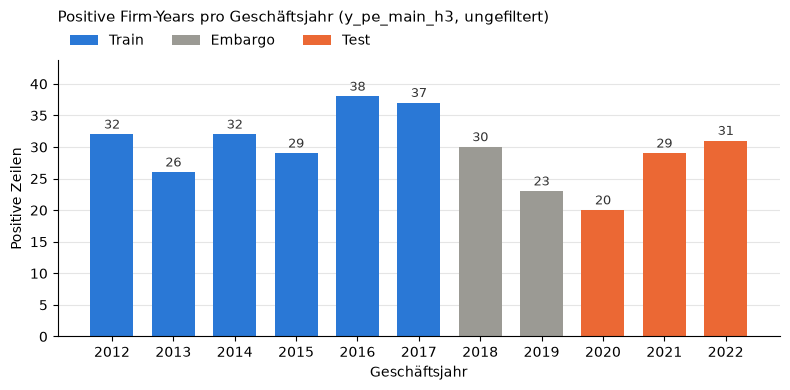

In [5]:
# Balkendiagramm: Positive (main) pro Jahr, eingefärbt nach Abschnitt.
# Embargo ist grau, weil diese Jahre später weder zum Schätzen noch zum Testen benutzt werden.
COLORS = {"Train": "#2a78d6", "Embargo": "#9b9a94", "Test": "#eb6834"}

fig, ax = plt.subplots(figsize=(8, 4))
for part, color in COLORS.items():
    sub = by_year[by_year["Abschnitt"] == part]
    bars = ax.bar(sub.index, sub["Positive_main"], color=color, width=0.7, label=part)
    ax.bar_label(bars, fontsize=9, color="#333333", padding=2)   # Zahl über jedem Balken

ax.set_title("Positive Firm-Years pro Geschäftsjahr (y_pe_main_h3, ungefiltert)", loc="left", fontsize=11, pad=28)
ax.set_xlabel("Geschäftsjahr")
ax.set_ylabel("Positive Zeilen")
ax.set_xticks(by_year.index)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
ax.set_axisbelow(True)
ax.set_ylim(0, by_year["Positive_main"].max() * 1.15)            # Platz für die Zahlen über den Balken
ax.legend(frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))  # Legende über dem Diagramm
plt.tight_layout()
plt.show()

**Ergebnis:** Jedes Jahr gibt es zwischen 20 und 38 positive Zeilen, der Anteil schwankt nur zwischen 0,4 % und 0,7 %. Es gibt also keinen Boom oder Einbruch, der Training und Test grundverschieden machen würde; 2020 (Corona) ist das schwächste Jahr. Das Training (2012–17) hat 194 Positive, der Test (2020–22) 80 – genug für eine Auswertung, aber wenig, weshalb die Testergebnisse später mit Unsicherheitsintervallen berichtet werden müssen.

## 4. Kennzahlen: Ziele vs. Nicht-Ziele (Median)

Wir vergleichen den **Median** (den mittleren Wert, wenn man alle Werte sortiert) statt des Durchschnitts, weil Finanzkennzahlen extreme Ausreißer haben – z. B. hat eine Firma mit fast null Eigenkapital ein riesiges Kurs-Buchwert-Verhältnis. Der Median reagiert darauf kaum.

In [6]:
features = ["roa", "sales_growth_1y", "cash_ratio", "leverage", "log_assets",
            "float_to_book", "float_to_earnings"]

# Gruppen bilden: 1 = wird in den nächsten 3 Jahren Ziel, 0 = nicht
group = obs["y_pe_main_h3"].map({1: "Positive (Ziel)", 0: "Negative"})
medians = obs.groupby(group)[features].median().T
medians = medians[["Positive (Ziel)", "Negative"]].round(3)

# Wie oft fehlt die Kennzahl (z. B. Verschuldung unsicher, kein Vorjahr für das Wachstum)?
medians["fehlend (alle Zeilen)"] = obs[features].isna().mean().map("{:.1%}".format)
display(medians)

# Wichtig zum Lesen von float_to_earnings: bei Verlust wird die Kennzahl negativ.
loss_share = obs.groupby(group)["float_to_earnings"].apply(lambda s: (s < 0).mean())
print("Anteil Zeilen mit Verlust (float_to_earnings < 0):")
print(loss_share.map("{:.1%}".format).to_string())

y_pe_main_h3,Positive (Ziel),Negative,fehlend (alle Zeilen)
roa,0.015,0.003,3.2%
sales_growth_1y,0.070,0.061,33.3%
cash_ratio,0.068,0.088,3.3%
leverage,0.244,0.127,3.5%
log_assets,20.583,19.717,1.8%
float_to_book,1.486,1.224,6.1%
float_to_earnings,5.788,1.569,4.5%


Anteil Zeilen mit Verlust (float_to_earnings < 0):
y_pe_main_h3
Negative           46.0%
Positive (Ziel)    36.4%


**Ergebnis:** Spätere Take-Private-Ziele sind im Median größer (`log_assets` 20,6 gegen 19,7, also rund 870 Mio. gegen 370 Mio. USD Bilanzsumme), etwa doppelt so hoch verschuldet (24 % gegen 13 % der Bilanzsumme) und etwas profitabler (ROA 1,5 % gegen 0,3 %). Beim Cash-Anteil liegen sie etwas niedriger, beim Umsatzwachstum und Kurs-Buchwert-Verhältnis nur leicht höher. Der große Unterschied bei `float_to_earnings` kommt vor allem daher, dass unter den Nicht-Zielen mehr Verlustfirmen mit negativem Wert sind – diese Kennzahl ist als Median deshalb schwer zu lesen. `sales_growth_1y` fehlt in einem Drittel der Zeilen: 2012 hat kein Vorjahr im Datensatz, und rund 15 % der Firmen melden keinen Umsatz-Tag.

*Vorsicht:* Ungefiltert stecken hier viele Kleinstfirmen und Mantelgesellschaften unter den Negativen – der Größenunterschied kann nach dem $50M-Float-Filter deutlich kleiner werden.

## Kernergebnisse

1. Panel und Kennzahlen passen zusammen: 71.713 Firmenjahre, davon 61.240 mit vollständig beobachtetem 3-Jahres-Fenster (2012–2022).
2. Take-Private-Ziele sind selten: 0,53 % der Firmenjahre (327 Zeilen, 136 Firmen) nach der Hauptdefinition, 0,45 % nach der strengen.
3. Die Positiven verteilen sich gleichmäßig über die Jahre (20–38 pro Jahr), sodass Train- und Testzeitraum vergleichbar sind.
4. Spätere Ziele sind im Median größer, höher verschuldet und etwas profitabler als andere börsennotierte Firmen.
5. Diese Vergleiche sind ungefiltert; nach den Stichprobenfiltern im nächsten Schritt müssen wir prüfen, ob die Unterschiede bestehen bleiben.